# Advanced Data Preparation with Python (Apartment Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped rental apartment data from Zurich. It is an exercise: complete the empty code cells. The solution is in advanced_data_preparation_apartment_data_solution.ipynb. 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [68]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/python_data_preparation


## Importing data

In [69]:
# Read the data to a pandas data frame
df = pd.read_csv('./Data/apartments_data_zuerich.csv',
                 sep=',',
                 encoding='utf-8')

# Show first records of data frame
df.head()

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«Gemütliche Wohnung im Grünen»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86..."
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«Attraktive 3.5-Zimmer-EG-Wohnung in Neerach»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,..."
2,1693998201-3,https://www.immoscout24.ch/de/immobilien/miete...,"19 m², CHF 2686.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 2686.—,«Studio Apartment Junior Balcony»,"19 m², CHF 2686.—Cramerstrasse 8-12, 8004 Züri..."
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 Bedroom Apartment Senior Balcony»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,..."
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 Bedroom Apartment Junior Terrace»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8..."


## Count number of rows and columns in the data frame

In [70]:
# Dimension (rows, columns)
shape = df.shape
print(f'Shape: {shape}')

# Number of rows
print(f'Rows: {shape[0]}')

# Number of columns
print(f'Cloumns: {shape[1]}')

Shape: (1008, 7)
Rows: 1008
Cloumns: 7


## Get data types (raw-format from web scraper)

In [71]:
# Get data types (note that in pandas, a string is referred to as 'object')
df.dtypes

web-scraper-order        str
web-scraper-start-url    str
rooms_area_price_raw     str
address_raw              str
price_raw                str
description_raw          str
text_raw                 str
dtype: object

## Extract information from raw data using regular expressions (regex)

### Extract number of rooms

In [72]:
# Extract values from 'rooms_area_price_raw' strings
rooms = []
for i in df['rooms_area_price_raw']:
    d1 = re.findall(r"(\d+,\d+|\d+)\s*Zimmer", i)
    try:
        d2 = d1[0].strip().replace(',', '.')
    except IndexError:
        d2 = None
    rooms.append(d2)

# Save as new variable in the pandas data frame
df['rooms'] = pd.Series(rooms, dtype="float64")

# Show first records of data frame
df[['rooms_area_price_raw', 'rooms']].head()

,rooms_area_price_raw,rooms
0,"3 Zimmer, 49 m², CHF 1441.—",3.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",2.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0


### Extract living area

In [73]:
# Extract values from 'rooms_area_price_raw' strings
area = []
for i in df['rooms_area_price_raw']:
    d1 = re.findall(r"(\d+)\s*m²", i)
    try:
        d2 = d1[0].strip()
    except IndexError:
        d2 = None
    area.append(d2)

# Save as new variable in the pandas data frame
df['area'] = pd.Series(area, dtype="Int64")

# Show first records of data frame
df[['rooms_area_price_raw', 'area']].head()

,rooms_area_price_raw,area
0,"3 Zimmer, 49 m², CHF 1441.—",49
1,"3,5 Zimmer, 65 m², CHF 1850.—",65
2,"19 m², CHF 2686.—",19
3,"2 Zimmer, 54 m², CHF 4853.—",54
4,"2 Zimmer, 49 m², CHF 4335.—",49


### Extract rental price

In [74]:
# Extract values from 'price_raw' strings
price = []
for i in df['price_raw']:
    d1 = re.findall(r"CHF\s*(\d+)\.—", i)
    try:
        d2 = d1[0].strip()
    except IndexError:
        d2 = None
    price.append(d2)

# Save as new variable in the pandas data frame
df['price'] = pd.Series(price, dtype="Int64")

# Show first records of data frame
df[['price_raw', 'price']].head()

,price_raw,price
0,CHF 1441.—,1441
1,CHF 1850.—,1850
2,CHF 2686.—,2686
3,CHF 4853.—,4853
4,CHF 4335.—,4335


### Get data types of all variables, including the new ones

In [75]:
# Get data types of all variables
df.dtypes

web-scraper-order            str
web-scraper-start-url        str
rooms_area_price_raw         str
address_raw                  str
price_raw                    str
description_raw              str
text_raw                     str
rooms                    float64
area                       Int64
price                      Int64
dtype: object

## Count and remove missing values

In [76]:
# Count missing values
print(f"Number of missing values: {pd.isna(df).sum().sum()}")

# Drop rows with missing values (if any)
df = df.dropna().reset_index(drop=True)

Number of missing values: 157


## Count and remove duplicated values

In [77]:
# Count duplicated values
duplicates_count = df.duplicated().sum()
print(f'Duplicates: {duplicates_count}')

# Drop rows with duplicated values (if any)
df.drop_duplicates(inplace=True)

# Dimension (rows, columns)
df.shape

Duplicates: 0


(861, 10)

## Use string manipulation methods to create additional variables from the apartment descriptions.

### Change strings in 'description_raw' and 'text_raw' to uppercase 

In [78]:
# Change strings in 'description_raw' to uppercase
df['description_raw'] = df["description_raw"].str.upper()

# Change strings in 'text_raw' to uppercase
df["text_raw"] = df["text_raw"].str.upper()


### Calculate length of strings in 'description_raw' and 'text_raw'

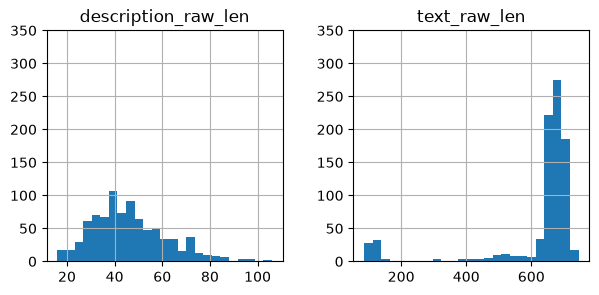

In [79]:
# Length of the strings in 'description_raw'
df["description_raw_len"] = df["description_raw"].str.len()

# Length of the strings in 'text_raw'
df["text_raw_len"] = df["text_raw"].str.len()

# Histogram of the length of the strings in 'description_raw' and 'text_raw'
ax = df[['description_raw_len', 'text_raw_len']].hist(bins=25,
                                                      figsize=(7, 3),)

# Set the y-axis range for each subplot
for axis in ax.flatten():
    axis.set_ylim(0, 350)

# Display the plot
plt.show()


### Create binary (0/1) variable 'luxurious'

In [80]:
df.head()

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms,area,price,description_raw_len,text_raw_len
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,"3 ZIMMER, 49 M², CHF 1441.—NEUHUSSTRASSE 6, 86...",3.0,49,1441,30,640
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,"3,5 ZIMMER, 65 M², CHF 1850.—ZÜRCHERSTRASSE 1,...",3.5,65,1850,45,658
2,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 BEDROOM APARTMENT SENIOR BALCONY»,"2 ZIMMER, 54 M², CHF 4853.—CRAMERSTRASSE 8-12,...",2.0,54,4853,36,695
3,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 BEDROOM APARTMENT JUNIOR TERRACE»,"2 ZIMMER, 49 M², CHF 4335.—ROTACHSTRASSE 33, 8...",2.0,49,4335,36,693
4,1693998201-16,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 32 m², CHF 3515.—","Wolframplatz 1, 8045 Zürich, ZH",CHF 3515.—,«2 BEDROOM APARTMENT MINI»,"2 ZIMMER, 32 M², CHF 3515.—WOLFRAMPLATZ 1, 804...",2.0,32,3515,26,681


In [81]:
# Create a pattern which can be used to search the variable 'description_raw'
pattern = 'LOFT|SEESICHT|PENTHOUSE|LUXUS'

# Create new variable 'luxurious' as binary dummy (0/1) variable
df['luxurious'] = df['description_raw'].str.contains(pat=pattern).astype(int)

# Count the number of luxurious apartments
print(df['luxurious'].sum())

# Show values
print(f'Luxerious count: {count}')

22
Luxerious count: 0


### Create variable 'price_per_m2'

In [82]:
# Create the new variable
df['price_per_m2'] = round(df['price'] / df['area'], 2)

# Show values
df[['description_raw', 'rooms', 'area', 'price', 'luxurious', 'price_per_m2']]

,description_raw,rooms,area,price,luxurious,price_per_m2
0,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,3.0,49,1441,0,29.41
1,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,3.5,65,1850,0,28.46
2,«2 BEDROOM APARTMENT SENIOR BALCONY»,2.0,54,4853,0,89.87
3,«2 BEDROOM APARTMENT JUNIOR TERRACE»,2.0,49,4335,0,88.47
4,«2 BEDROOM APARTMENT MINI»,2.0,32,3515,0,109.84
...,...,...,...,...,...,...
856,"«CHARMANTE WOHNUNG IN HOTTINGEN, NÄHE RÖMERHOF»",3.5,82,2830,0,34.51
857,«HEIMELIGE 4-ZIMMER-WOHNUNG IN WINTERTHUR-HEGI»,4.0,73,1713,0,23.47
858,«EXKLUSIVE WOHNUNG FÜR HÖCHSTE ANSPRÜCHE - MIT...,4.5,110,3500,1,31.82
859,«MODERNE WOHNUNG AN RUHIGER LAGE»,3.0,68,1650,0,24.26


### Include current datetime as time stamp

In [83]:
# Get and format datetime
df['datetime'] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# Show values
df.head()

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms,area,price,description_raw_len,text_raw_len,luxurious,price_per_m2,datetime
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,"3 ZIMMER, 49 M², CHF 1441.—NEUHUSSTRASSE 6, 86...",3.0,49,1441,30,640,0,29.41,2026-10-13 07:29:08
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,"3,5 ZIMMER, 65 M², CHF 1850.—ZÜRCHERSTRASSE 1,...",3.5,65,1850,45,658,0,28.46,2026-10-13 07:29:08
2,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 BEDROOM APARTMENT SENIOR BALCONY»,"2 ZIMMER, 54 M², CHF 4853.—CRAMERSTRASSE 8-12,...",2.0,54,4853,36,695,0,89.87,2026-10-13 07:29:08
3,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 BEDROOM APARTMENT JUNIOR TERRACE»,"2 ZIMMER, 49 M², CHF 4335.—ROTACHSTRASSE 33, 8...",2.0,49,4335,36,693,0,88.47,2026-10-13 07:29:08
4,1693998201-16,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 32 m², CHF 3515.—","Wolframplatz 1, 8045 Zürich, ZH",CHF 3515.—,«2 BEDROOM APARTMENT MINI»,"2 ZIMMER, 32 M², CHF 3515.—WOLFRAMPLATZ 1, 804...",2.0,32,3515,26,681,0,109.84,2026-10-13 07:29:08


## Discretization of numerical data

In [84]:
# Discretization of the variable 'price_per_m2'
df['price_per_m2_cat'] = pd.cut(df['price_per_m2'],
                                bins=5,
                                labels=['very cheap',
                                        'cheap',
                                        'normal',
                                        'expensive',
                                        'very expensive'])

# Show unique values
df['price_per_m2_cat'].unique()


['very cheap', 'normal', 'expensive', 'cheap', 'very expensive']
Categories (5, str): ['very cheap' < 'cheap' < 'normal' < 'expensive' < 'very expensive']

## One Hot Encoding

In [106]:
# One Hot Encoding of the variable 'price_per_m2_cat'
try:
    df = pd.get_dummies(df,
                        columns=['price_per_m2_cat'],
                        drop_first=False)
except KeyError:
    print("Dummy variables already exist")

# Convert boolean values to integers (0 and 1)
dummy_cols = df.filter(like='price_per_m2_cat').columns
df[dummy_cols] = df[dummy_cols].astype(int)

# Show values of the new dummy variables
df.filter(like='price_per_m2_cat').head()


Dummy variables already exist


,price_per_m2_cat_very cheap,price_per_m2_cat_cheap,price_per_m2_cat_normal,price_per_m2_cat_expensive,price_per_m2_cat_very expensive
0,1,0,0,0,0
1,1,0,0,0,0
2,0,0,1,0,0
3,0,0,1,0,0
4,0,0,0,1,0


## Scaling

### Min-Max Scaling

#### By hand

In [109]:
# Min-Max scaling of the variable 'area' (by hand)
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(df['area'])
print(scaler)
# Histogram of the variable 'area' and 'area_scaled_minmax'


# Set the y-axis range for each subplot and add labels


# Display the plot


MinMaxScaler(feature_range=0       49
1       65
2       54
3       49
4       32
      ... 
856     82
857     73
858    110
859     68
860    114
Name: area, Length: 861, dtype: Int64)


#### scikit-learn version

In [87]:
# Min-Max scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Max-Absolute Scaling

#### By hand

In [88]:
# Max-Absolute scaling of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_max_abs'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [89]:
# Max-Absolute scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Robust Scaling

#### By hand

In [90]:
# Robust scaling of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_robust'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [91]:
# Robust scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


## Standardization

### Z-score Normalization

#### By hand

In [92]:
# Z-score Normalization of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_z'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [93]:
# Z-score Normalization of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly


# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)


## Transformation

### Log-Transformation

In [94]:
# Log-Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_log'


# Set the y-axis range for each subplot and add labels


# Display the plot


### SQRT-Transformation

In [95]:
# SQRT-Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_sqrt'


# Set the y-axis range for each subplot and add labels


# Display the plot


### Box-Cox Transformation

In [96]:
# Import the boxcox function from scipy


# Box-Cox Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_boxcox'


# Set the y-axis range for each subplot and add labels


# Display the plot


## Combining & organizing data

### Reading rental apartment data with geocoded addresses

In [97]:
# Meaning of variables
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name

# Geocoded data (i.e. data with latitude and longitude)


# Show data


### Join geo-information to rental apartment data using .merge()

In [98]:
# Merge geo-information to the apartment data (the key is 'web-scraper-order')


# Show data


### Reading municipality-level data

In [99]:
# Meaning of variables:
# bfs_number: municipality id
# bfs_name: municipality name
# pop: number of residents
# pop_dens: population density per km2
# frg_pct: percentage foreigners
# emp: number of employees

# Read municipality-level data from the .xlsx file


# Show data


### Join municipality data to rental apartment data using .merge()

In [100]:
# Merge needs a key which must be identical in both data sets
# (here the key is 'bfs_number')


# Show data


## Sorting data

In [101]:
# Sorting data by 'price' and 'area' with highest price above (ascending=False)


# Show data


## Reshaping data

### Reshaping data using .stack() and .unstack()

In [102]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .stack()


# Reshape the data back using .unstack()


### Reshaping data using .melt()

In [103]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .melt()


### Pivoting data using .pivot_table()

In [104]:
# Create a pivot table with the mean values per number of rooms


# Format the values to 2 decimal places with trailing zeros


# Display the pivot table


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [105]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-13 07:29:08
Python Version: 3.11.16
-----------------------------------
